In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

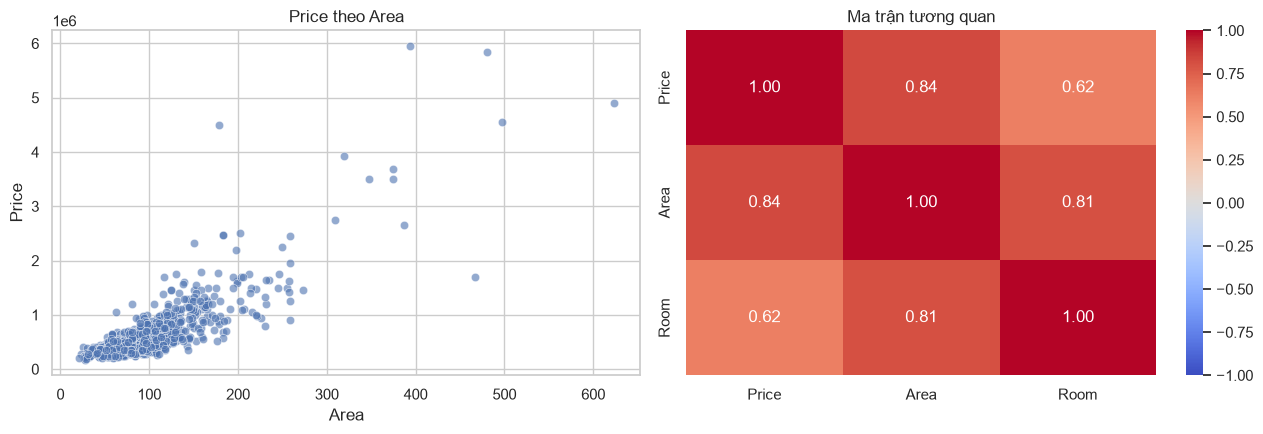

In [13]:
hp = pd.read_csv("data/HousingPrices-Amsterdam-August-2021.csv")[['Price', 'Area', 'Room']].dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=hp, x='Area', y='Price', alpha=.6, ax=ax[0])          # scatter plot
ax[0].set_title('Price theo Area')
sns.heatmap(hp.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax[1])   # heatmap tương quan
ax[1].set_title('Ma trận tương quan')
plt.tight_layout(); plt.show()

## Bài toán 1 – Nhiệm vụ 1: Phân tích đơn biến dữ liệu chim cánh cụt

In [14]:
raw = pd.read_csv("data/penguins_lter.csv")
penguins_full = pd.DataFrame({
    'species': raw['Species'].str.split().str[0],        # 'Adelie Penguin (...)' -> 'Adelie'
    'culmen_length_mm': raw['Culmen Length (mm)'],
    'body_mass_g': raw['Body Mass (g)'],
    'sex': raw['Sex'].replace('.', np.nan)})
print(penguins_full.shape)
print(penguins_full.isna().sum())
penguins_full.head()

(344, 4)
species              0
culmen_length_mm     2
body_mass_g          2
sex                 11
dtype: int64


,species,culmen_length_mm,body_mass_g,sex
0,Adelie,39.1,3750.0,MALE
1,Adelie,39.5,3800.0,FEMALE
2,Adelie,40.3,3250.0,FEMALE
3,Adelie,NaN,NaN,NaN
4,Adelie,36.7,3450.0,FEMALE


In [15]:
penguins_data = penguins_full[['species', 'culmen_length_mm']]
penguins_data.describe(include='all')

,species,culmen_length_mm
count,344,342.000000
unique,3,NaN
top,Adelie,NaN
freq,152,NaN
mean,NaN,43.921930
std,NaN,5.459584
min,NaN,32.100000
25%,NaN,39.225000
50%,NaN,44.450000
75%,NaN,48.500000


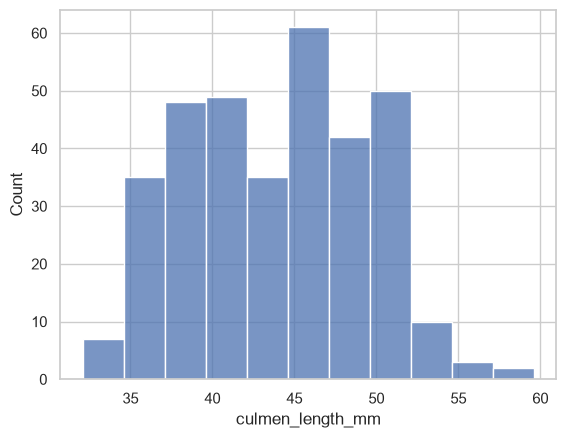

In [16]:
# case 1: basic
sns.histplot(data=penguins_data, x=penguins_data["culmen_length_mm"])
plt.show()

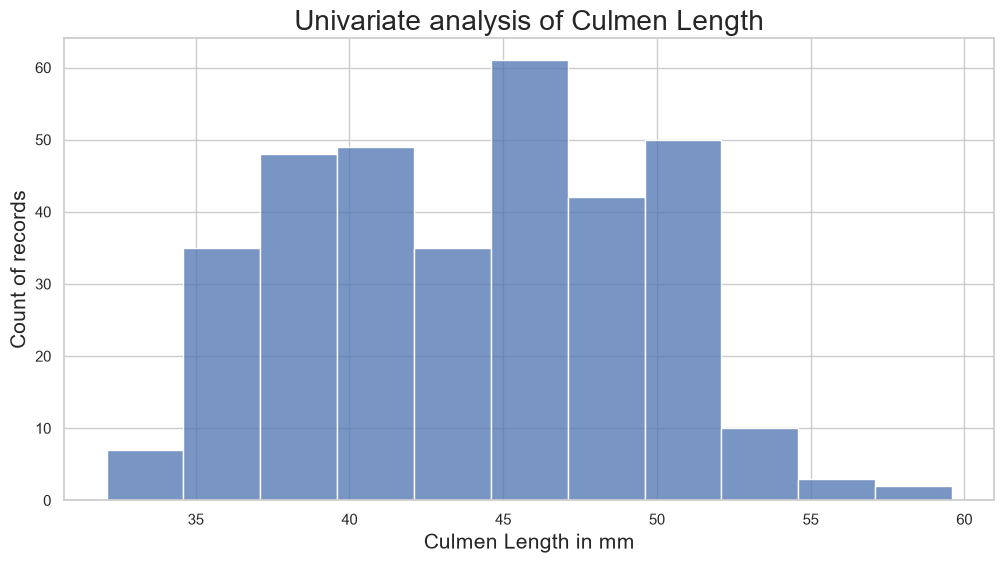

In [17]:
# case 2: advanced
plt.figure(figsize=(12, 6))
ax = sns.histplot(data=penguins_data, x=penguins_data["culmen_length_mm"])
ax.set_xlabel('Culmen Length in mm', fontsize=15)
ax.set_ylabel('Count of records', fontsize=15)
ax.set_title('Univariate analysis of Culmen Length', fontsize=20)
plt.show()

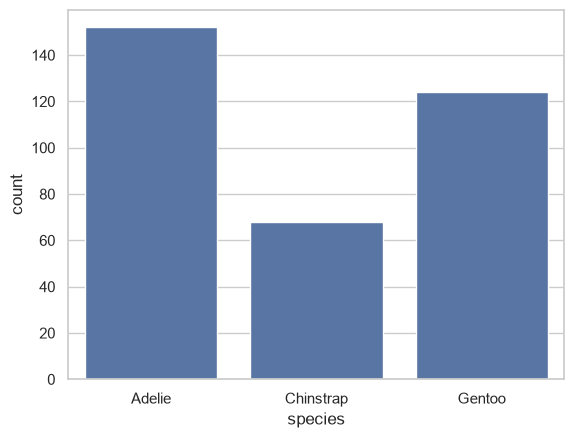

In [18]:
# case 1: basic
sns.countplot(data=penguins_data, x=penguins_data['species'])
plt.show()

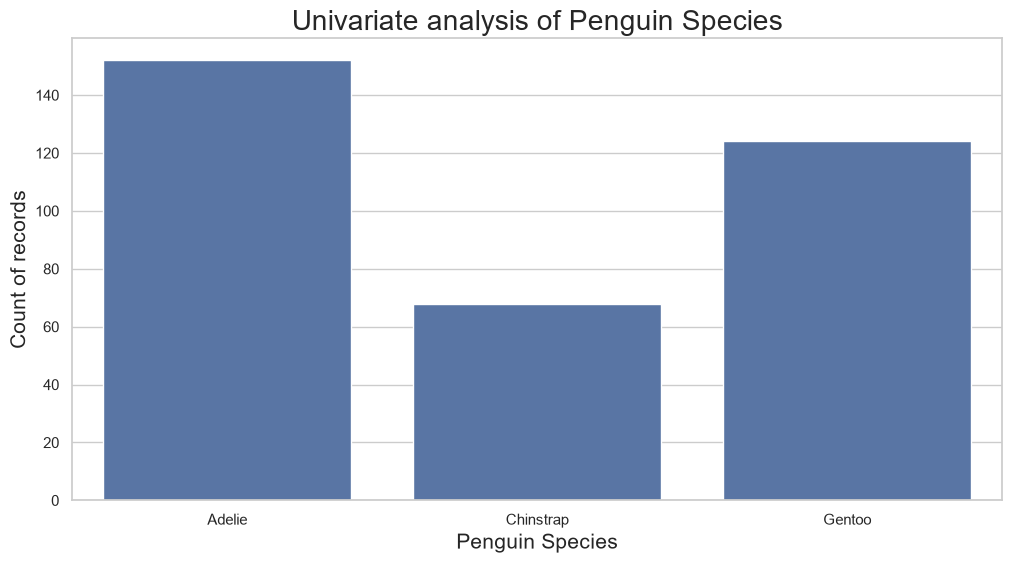

In [19]:
# case 2: advanced
plt.figure(figsize=(12, 6))
ax = sns.countplot(data=penguins_data, x=penguins_data['species'])
ax.set_xlabel('Penguin Species', fontsize=15)
ax.set_ylabel('Count of records', fontsize=15)
ax.set_title('Univariate analysis of Penguin Species', fontsize=20)   # (lab đặt tiêu đề 2 lần, chỉ cần 1 dòng)
plt.show()

species
Adelie       152
Chinstrap     68
Gentoo       124
Name: count, dtype: int64


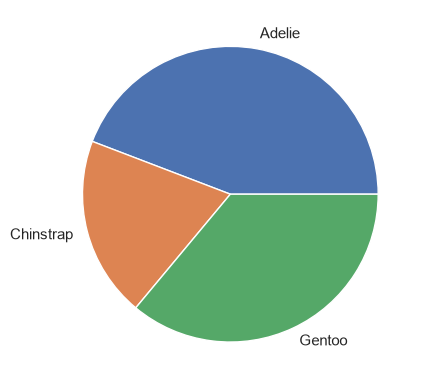

In [20]:
species_count = penguins_data['species'].value_counts().sort_index()
print(species_count)
# case 1: basic
plt.pie(species_count, labels=species_count.index)
plt.show()

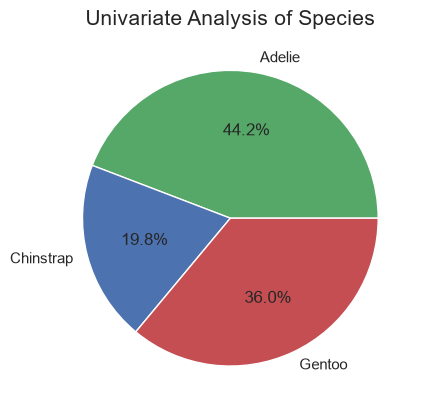

In [21]:
# case 2: advanced
cols = ['g', 'b', 'r']
plt.pie(species_count, labels=species_count.index, colors=cols, autopct='%1.1f%%')
plt.title('Univariate Analysis of Species', fontsize=15)
plt.show()

## Bài toán 1 – Nhiệm vụ 2: Phân tích đơn biến dữ liệu giá nhà Amsterdam

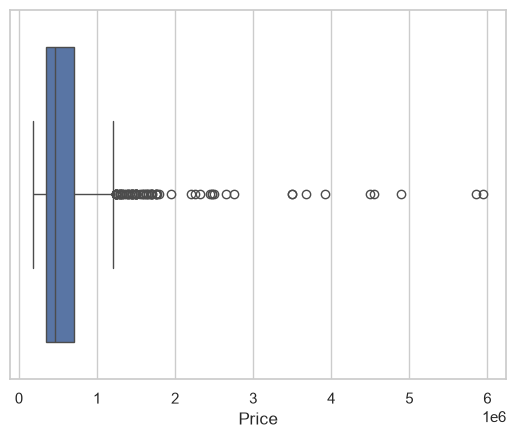

In [22]:
houseprices_data = pd.read_csv("data/HousingPrices-Amsterdam-August-2021.csv")
houseprices_data = houseprices_data[['Zip', 'Price', 'Area', 'Room']]
# case 1: basic boxplot
sns.boxplot(data=houseprices_data, x=houseprices_data["Price"])
plt.show()

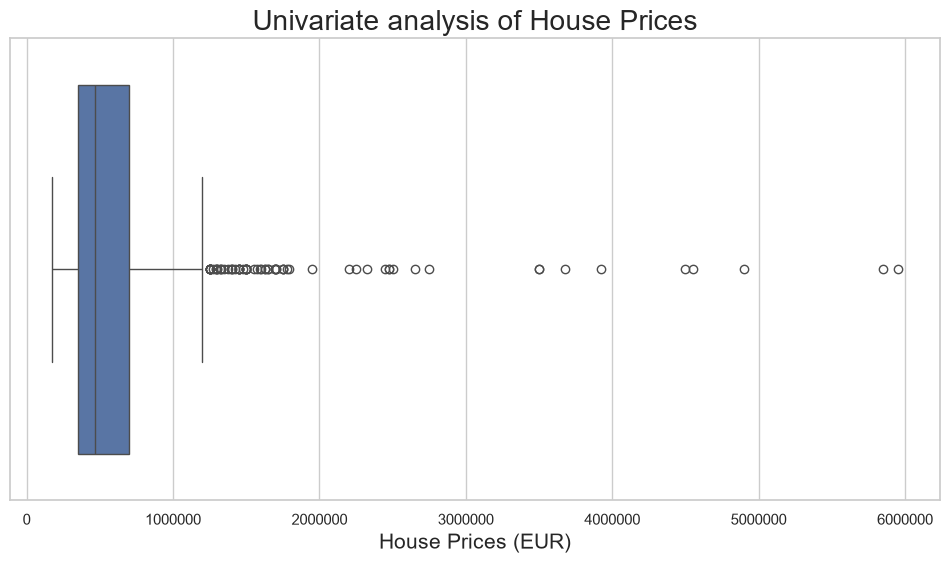

In [23]:
# case 2: advanced
plt.figure(figsize=(12, 6))
ax = sns.boxplot(data=houseprices_data, x=houseprices_data["Price"])
ax.set_xlabel('House Prices (EUR)', fontsize=15)
ax.set_title('Univariate analysis of House Prices', fontsize=20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

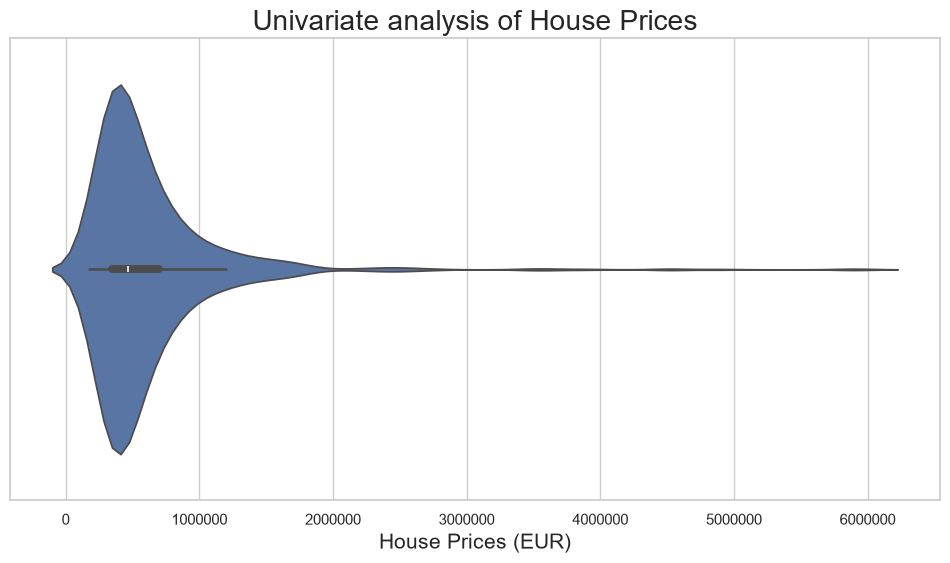

In [24]:
plt.figure(figsize=(12, 6))
ax = sns.violinplot(data=houseprices_data, x=houseprices_data["Price"])
ax.set_xlabel('House Prices (EUR)', fontsize=15)
ax.set_title('Univariate analysis of House Prices', fontsize=20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

In [25]:
houseprices_data.describe()

,Price,Area,Room
count,9.200000e+02,924.000000,924.000000
mean,6.220654e+05,95.952381,3.571429
std,5.389942e+05,57.447436,1.592332
min,1.750000e+05,21.000000,1.000000
25%,3.500000e+05,60.750000,3.000000
50%,4.670000e+05,83.000000,3.000000
75%,7.000000e+05,113.000000,4.000000
max,5.950000e+06,623.000000,14.000000


In [26]:
price = houseprices_data['Price'].dropna()
q1, q3 = price.quantile([.25, .75]); iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1 = {q1:,.0f} | Median = {price.median():,.0f} | Q3 = {q3:,.0f} | IQR = {iqr:,.0f}")
print(f"Ngưỡng ngoại lai trên (Q3 + 1.5*IQR) = {upper:,.0f}")
print(f"Số căn nhà có giá vượt ngưỡng: {(price > upper).sum()} ({(price > upper).mean()*100:.1f}%)")
print(f"Skewness của Price = {price.skew():.2f}")

Q1 = 350,000 | Median = 467,000 | Q3 = 700,000 | IQR = 350,000
Ngưỡng ngoại lai trên (Q3 + 1.5*IQR) = 1,225,000
Số căn nhà có giá vượt ngưỡng: 71 (7.7%)
Skewness của Price = 4.83


## Bài toán 2 – Nhiệm vụ 1: Phân tích hai biến dữ liệu chim cánh cụt

In [27]:
penguins_data = penguins_full[['species', 'culmen_length_mm', 'body_mass_g', 'sex']]
penguins_data.head()

,species,culmen_length_mm,body_mass_g,sex
0,Adelie,39.1,3750.0,MALE
1,Adelie,39.5,3800.0,FEMALE
2,Adelie,40.3,3250.0,FEMALE
3,Adelie,NaN,NaN,NaN
4,Adelie,36.7,3450.0,FEMALE


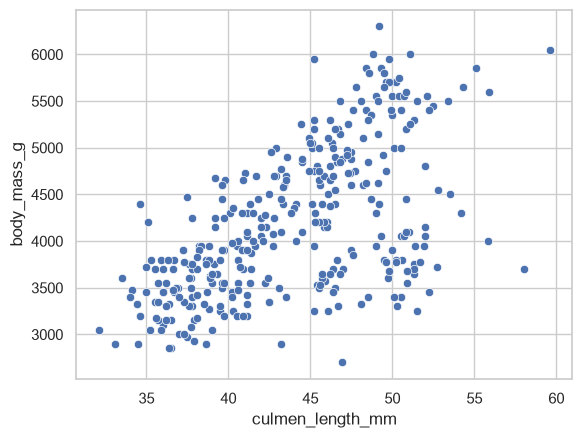

In [28]:
# case 1: basic
sns.scatterplot(data=penguins_data, x=penguins_data["culmen_length_mm"], y=penguins_data['body_mass_g'])
plt.show()

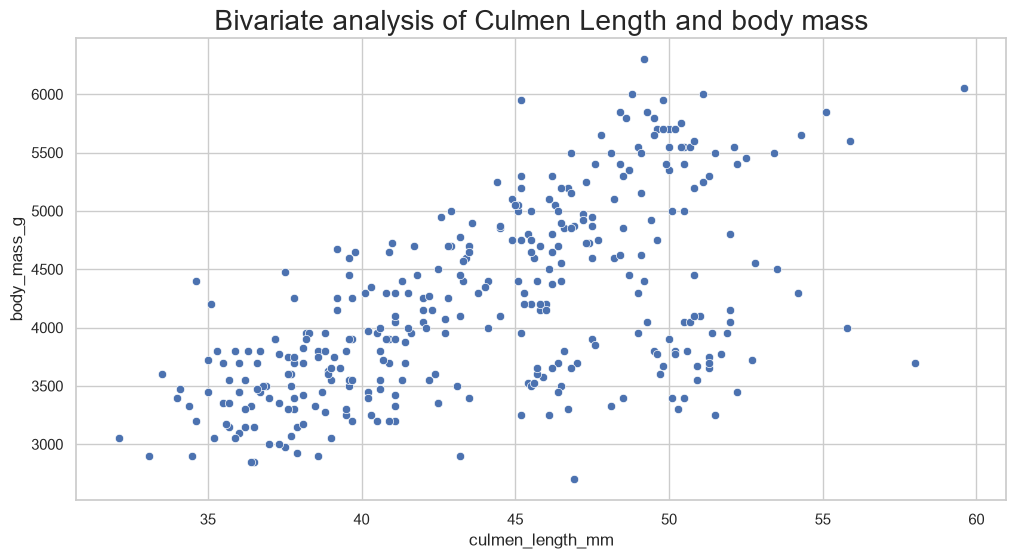

In [29]:
# case 2: advanced
plt.figure(figsize=(12, 6))
ax = sns.scatterplot(data=penguins_data, x=penguins_data["culmen_length_mm"], y=penguins_data['body_mass_g'])
ax.set_title('Bivariate analysis of Culmen Length and body mass', fontsize=20)
plt.show()

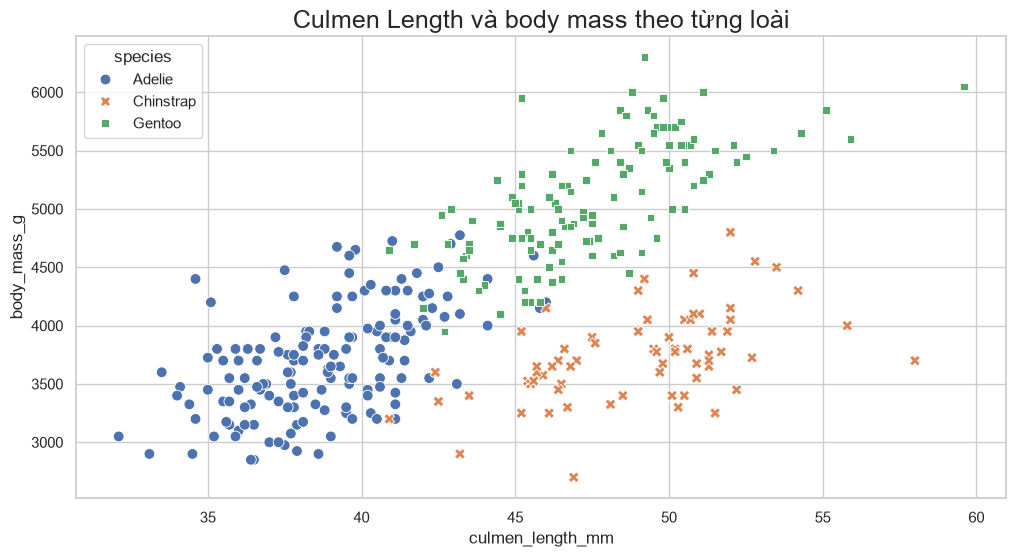

Tương quan chung (Pearson): 0.595
species                    
Adelie     culmen_length_mm    0.549
Chinstrap  culmen_length_mm    0.514
Gentoo     culmen_length_mm    0.669
Name: tương quan trong từng loài, dtype: float64


In [30]:
plt.figure(figsize=(12, 6))
ax = sns.scatterplot(data=penguins_data, x='culmen_length_mm', y='body_mass_g', hue='species', style='species', s=60)
ax.set_title('Culmen Length và body mass theo từng loài', fontsize=18)
plt.show()
print("Tương quan chung (Pearson):", round(penguins_data['culmen_length_mm'].corr(penguins_data['body_mass_g']), 3))
print(penguins_data.groupby('species')[['culmen_length_mm', 'body_mass_g']].corr().iloc[0::2, -1].round(3).rename('tương quan trong từng loài'))

In [31]:
pd.crosstab(index=penguins_data['species'], columns=penguins_data['sex'])

sex,FEMALE,MALE
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


In [32]:
pd.pivot_table(penguins_data, values='culmen_length_mm', index='species', aggfunc=np.mean)

,culmen_length_mm
species,
Adelie,38.791391
Chinstrap,48.833824
Gentoo,47.504878


In [33]:
pd.pivot_table(penguins_data, values=['culmen_length_mm', 'body_mass_g'], index='species', columns='sex', aggfunc='mean').round(1)

body_mass_g         culmen_length_mm      
sex            FEMALE    MALE           FEMALE  MALE
species                                             
Adelie         3368.8  4043.5             37.3  40.4
Chinstrap      3527.2  3939.0             46.6  51.1
Gentoo         4679.7  5484.8             45.6  49.5

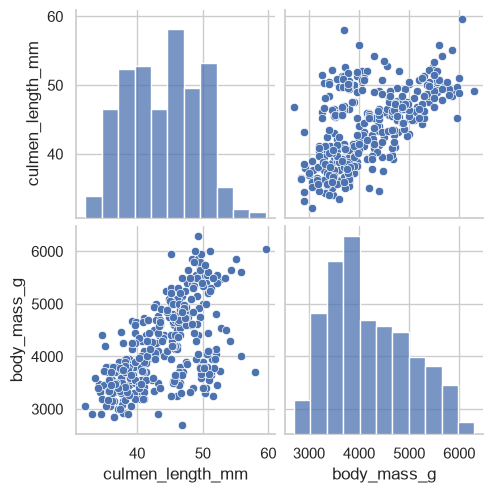

In [34]:
sns.pairplot(data=penguins_data[['species', 'culmen_length_mm', 'body_mass_g']])
plt.show()

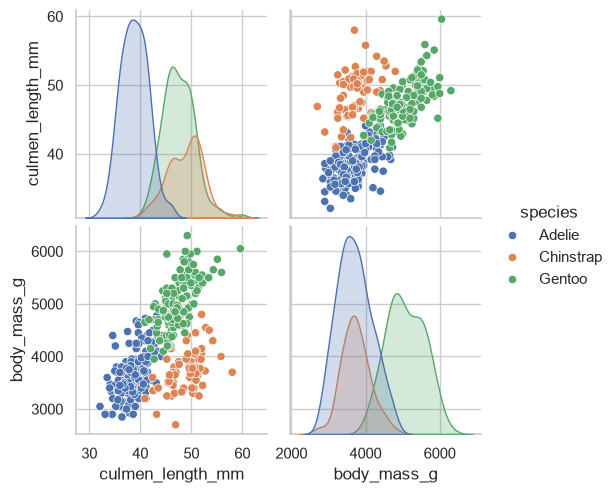

In [35]:
sns.pairplot(data=penguins_data[['species', 'culmen_length_mm', 'body_mass_g']], hue='species')
plt.show()

In [36]:
num = penguins_data[['culmen_length_mm', 'body_mass_g']].dropna()
print("Hiệp biến (covariance):\n", num.cov().round(2), "\n")
print("Tương quan (correlation):\n", num.corr().round(3), "\n")
# hiệp biến phụ thuộc đơn vị đo, tương quan thì không: đổi gram -> kilogram
num_kg = num.assign(body_mass_g=num['body_mass_g'] / 1000)
print("Sau khi đổi body_mass sang kg: cov =", round(num_kg.cov().iloc[0, 1], 3), "| corr =", round(num_kg.corr().iloc[0, 1], 3))

Hiệp biến (covariance):
                   culmen_length_mm  body_mass_g
culmen_length_mm             29.81      2605.59
body_mass_g                2605.59    643131.08 

Tương quan (correlation):
                   culmen_length_mm  body_mass_g
culmen_length_mm             1.000        0.595
body_mass_g                  0.595        1.000 

Sau khi đổi body_mass sang kg: cov = 2.606 | corr = 0.595


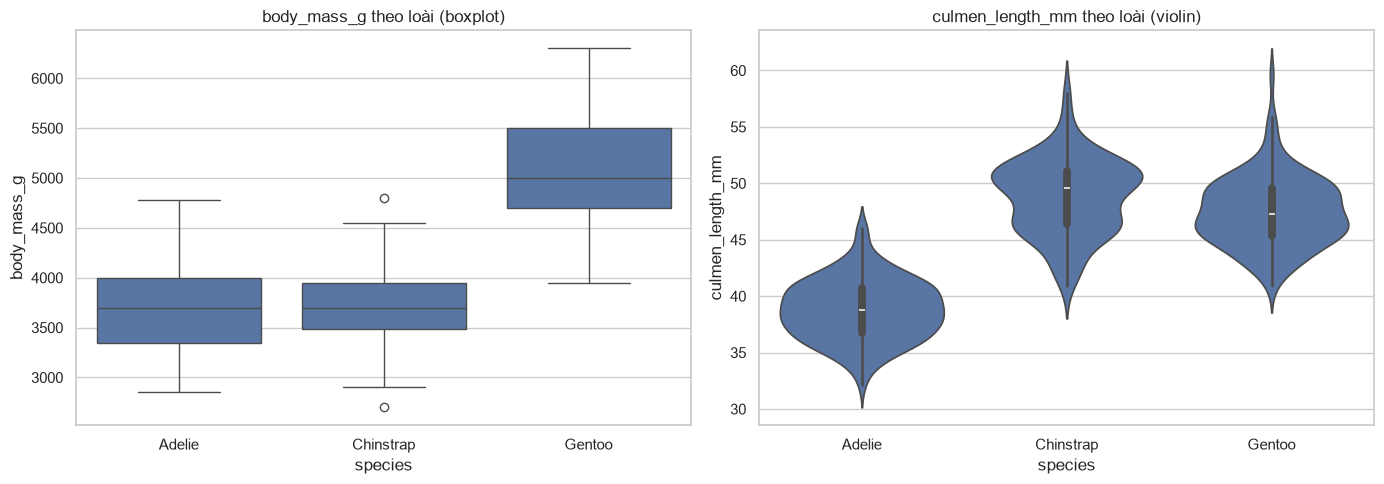

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=penguins_data, x='species', y='body_mass_g', ax=ax[0]); ax[0].set_title('body_mass_g theo loài (boxplot)')
sns.violinplot(data=penguins_data, x='species', y='culmen_length_mm', ax=ax[1]); ax[1].set_title('culmen_length_mm theo loài (violin)')
plt.tight_layout(); plt.show()

## Bài toán 3 – Công cụ EDA tự động
Các ô dưới đây là code cần chạy **trên máy của nhóm** (cần cài thư viện và mở trình duyệt). Dữ liệu dùng là Customer Personality Analysis (`marketing_campaign.csv`, ngăn cách bằng tab).

Cài đặt (chạy một lần):

In [38]:
%pip install ydata-profiling dtale sweetviz autoviz

Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,

In [39]:
import pandas as pd
from ydata_profiling import ProfileReport

os.makedirs('Reports', exist_ok=True)
marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t')   # file ngăn cách bằng tab

profile = ProfileReport(marketing_data, title="Marketing Campaign - Profiling Report")
profile.to_file("Reports/profile_output.html")   # mở file HTML này bằng trình duyệt
# profile.to_notebook_iframe()                   # hoặc xem trực tiếp trong notebook

ModuleNotFoundError: No module named 'ydata_profiling'

In [ ]:
import dtale

marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t')
d = dtale.show(marketing_data)
d.open_browser()

## Bài tập thực hành 1 – SweetViz trên tập Marketing Campaign


In [ ]:
import sweetviz as sv

marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t')

# 1) Báo cáo tổng quan toàn bộ dữ liệu
report = sv.analyze(marketing_data)
report.show_html('Reports/sweetviz_report.html')

# 2) Phân tích theo biến mục tiêu Response (khách hàng có phản hồi chiến dịch hay không)
report_target = sv.analyze(marketing_data, target_feat='Response')
report_target.show_html('Reports/sweetviz_target_response.html')

# 3) So sánh hai nhóm trong cùng tập dữ liệu: có con nhỏ và không có con nhỏ
report_cmp = sv.compare_intra(marketing_data, marketing_data['Kidhome'] > 0,
                              ['Co con nho', 'Khong co con nho'])
report_cmp.show_html('Reports/sweetviz_compare_kidhome.html')

## Bài tập thực hành 2 – AutoViz trên tập Marketing Campaign


In [ ]:
from autoviz.AutoViz_Class import AutoViz_Class

AV = AutoViz_Class()
# depVar là biến mục tiêu (tùy chọn); chart_format='html' hoặc 'svg' tùy phiên bản thư viện
df_viz = AV.AutoViz("data/marketing_campaign.csv", sep='\t', depVar='Response',
                    verbose=1, chart_format='svg')